<a href="https://colab.research.google.com/github/raina1234-a/Starbucks-customer-segmentation/blob/main/starbucks_segmentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score

In [2]:
portfolio = pd.read_csv("/content/portfolio.csv")
profile = pd.read_csv("/content/profile.csv")
transcript = pd.read_csv("/content/transcript.csv")

print("Portfolio:", portfolio.shape)
print("Profile:", profile.shape)
print("Transcript:", transcript.shape)

Portfolio: (10, 7)
Profile: (17000, 6)
Transcript: (20836, 5)


Offers received 12650
Offers viewed   4844 (38.3% of received)
Offers completed 822 (6.5% of received)


/tmp/ipykernel_4447/2892966715.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=events_to_plot, y=counts, palette="viridis")


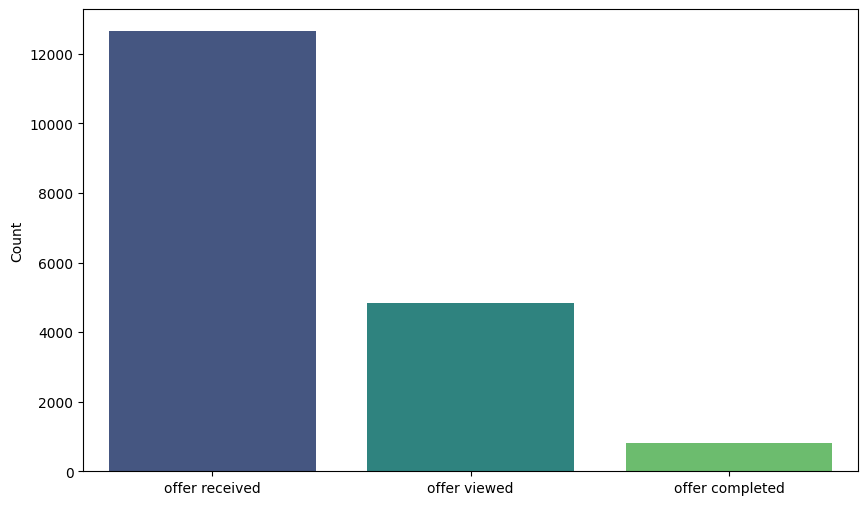

In [3]:
event_counts = transcript['event'].value_counts()
total_events = len(transcript)

n_received = event_counts.get('offer received', 0)
n_viewed = event_counts.get('offer viewed', 0)
n_completed = event_counts.get('offer completed', 0)

print(f"Offers received {n_received}")
print(f"Offers viewed   {n_viewed} ({n_viewed/n_received*100:.1f}% of received)")
print(f"Offers completed {n_completed} ({n_completed/n_received*100:.1f}% of received)")

#Visualization
events_to_plot = ['offer received', 'offer viewed', 'offer completed']
counts = [n_received, n_viewed, n_completed]

plt.figure(figsize=(10, 6))
sns.barplot(x=events_to_plot, y=counts, palette="viridis")
plt.ylabel("Count")
plt.show()

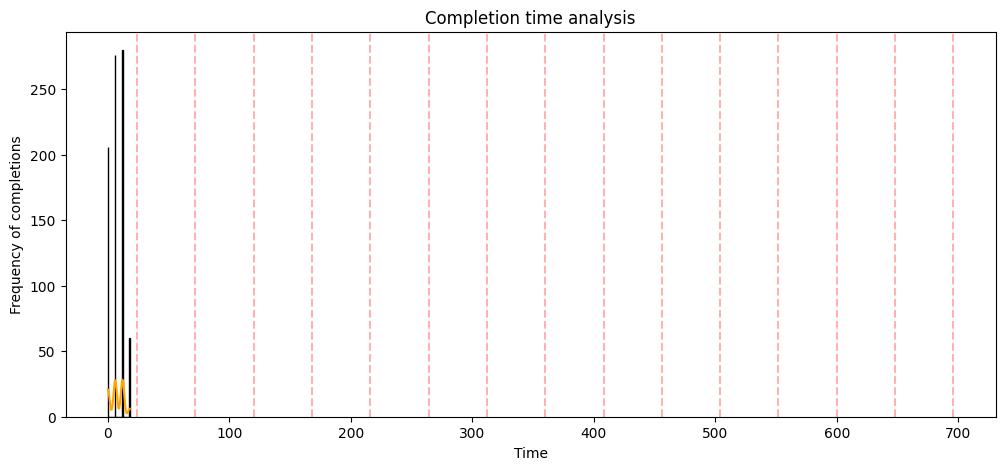

In [4]:
completed_data = transcript[transcript['event'] == 'offer completed']

plt.figure(figsize=(12, 5))
sns.histplot(completed_data['time'], bins=50, kde=True, color='orange')
plt.title("Completion time analysis")
plt.xlabel("Time")
plt.ylabel("Frequency of completions")

for day in range(1, 30, 2):
    plt.axvline(day * 24, color='red', linestyle='--', alpha=0.3)

plt.show()

In [5]:
# profile cleaning
if 'id' in profile.columns:
    profile.rename(columns={'id': 'customer_id'}, inplace=True)

profile['age'] = profile['age'].replace(118, np.nan)
profile['income'] = profile['income'].fillna(profile['income'].median())
profile['gender'] = profile['gender'].fillna('O') # O for Unknown

if 'became_member_on' in profile.columns:
    profile['became_member_on'] = pd.to_datetime(profile['became_member_on'], format='%Y%m%d')

In [6]:
# portfolio cleaning
if 'id' in portfolio.columns:
    portfolio.rename(columns={'id': 'offer_id'}, inplace=True)

channel_cols = [c for c in portfolio.columns if 'channels' in c]

for ch in ['web', 'email', 'mobile', 'social']:
    portfolio[ch] = 0

for index, row in portfolio.iterrows():
    row_channels = str([row[c] for c in channel_cols])

    if 'web' in row_channels: portfolio.at[index, 'web'] = 1
    if 'email' in row_channels: portfolio.at[index, 'email'] = 1
    if 'mobile' in row_channels: portfolio.at[index, 'mobile'] = 1
    if 'social' in row_channels: portfolio.at[index, 'social'] = 1

portfolio.drop(columns=channel_cols, inplace=True)

In [7]:
# transcript cleaning
if 'person' in transcript.columns:
    transcript.rename(columns={'person': 'customer_id'}, inplace=True)

cols = transcript.columns
if 'value/offer id' in cols and 'value/offer_id' in cols:
    transcript['offer_id'] = transcript['value/offer id'].combine_first(transcript['value/offer_id'])
elif 'value/offer id' in cols:
    transcript['offer_id'] = transcript['value/offer id']
elif 'value/offer_id' in cols:
    transcript['offer_id'] = transcript['value/offer_id']

if 'value/amount' in cols:
    transcript.rename(columns={'value/amount': 'amount'}, inplace=True)

messy_cols = ['value/offer id', 'value/offer_id', 'value/reward', 'value']
transcript.drop(columns=[c for c in messy_cols if c in transcript.columns], inplace=True)

In [9]:
print("Transcript:", transcript.columns.tolist())
print("Profile:", profile.columns.tolist())
print("Portfolio:", portfolio.columns.tolist())
print("Merged:", merged_df.columns.tolist())

Transcript: ['Unnamed: 0', 'customer_id', 'event', 'time']
Profile: ['Unnamed: 0', 'gender', 'age', 'customer_id', 'became_member_on', 'income']
Portfolio: ['Unnamed: 0', 'reward', 'difficulty', 'duration', 'offer_type', 'offer_id', 'web', 'email', 'mobile', 'social']
Merged: ['Unnamed: 0_x', 'customer_id', 'event', 'time', 'Unnamed: 0_y', 'gender', 'age', 'became_member_on', 'income']


In [10]:
print(transcript.head(10).to_string(index=False))
print("\nEvent counts:")
print(transcript['event'].value_counts())

 Unnamed: 0                      customer_id          event  time
          0 78afa995795e4d85b5d9ceeca43f5fef offer received   0.0
          1 a03223e636434f42ac4c3df47e8bac43 offer received   0.0
          2 e2127556f4f64592b11af22de27a7932 offer received   0.0
          3 8ec6ce2a7e7949b1bf142def7d0e0586 offer received   0.0
          4 68617ca6246f4fbc85e91a2a49552598 offer received   0.0
          5 389bc3fa690240e798340f5a15918d5c offer received   0.0
          6 c4863c7985cf408faee930f111475da3 offer received   0.0
          7 2eeac8d8feae4a8cad5a6af0499a211d offer received   0.0
          8 aa4862eba776480b8bb9c68455b8c2e1 offer received   0.0
          9 31dda685af34476cad5bc968bdb01c53 offer received   0.0

Event counts:
event
offer received     12650
offer viewed        4844
transaction         2520
offer completed      822
Name: count, dtype: int64


In [12]:
transcript_original = pd.read_csv(
    'transcript.csv'
)

print(transcript_original.columns.tolist())
display(transcript_original.head(3))

['Unnamed: 0', 'person', 'event', 'value', 'time']


,Unnamed: 0,person,event,value,time
0,0,78afa995795e4d85b5d9ceeca43f5fef,offer received,{'offer id': '9b98b8c7a33c4b65b9aebfe6a799e6d9'},0
1,1,a03223e636434f42ac4c3df47e8bac43,offer received,{'offer id': '0b1e1539f2cc45b7b9fa7c272da2e1d7'},0
2,2,e2127556f4f64592b11af22de27a7932,offer received,{'offer id': '2906b810c7d4411798c6938adc9daaa5'},0


In [13]:

import pandas as pd
import ast

# Restore transcript from the original CSV
transcript_clean = transcript_original.copy()

# Rename the customer identifier
transcript_clean.rename(
    columns={'person': 'customer_id'},
    inplace=True
)

# Remove the saved index column
if 'Unnamed: 0' in transcript_clean.columns:
    transcript_clean.drop(columns=['Unnamed: 0'], inplace=True)

# Extract offer IDs from the value column
def extract_offer_id(value):
    if isinstance(value, dict):
        return value.get('offer id')

    if isinstance(value, str):
        try:
            parsed = ast.literal_eval(value)
            if isinstance(parsed, dict):
                return parsed.get('offer id')
        except (ValueError, SyntaxError):
            pass

    return None

transcript_clean['offer_id'] = (
    transcript_clean['value'].apply(extract_offer_id)
)

# Inspect the result
display(transcript_clean.head())
print(transcript_clean.columns.tolist())

,customer_id,event,value,time,offer_id
0,78afa995795e4d85b5d9ceeca43f5fef,offer received,{'offer id': '9b98b8c7a33c4b65b9aebfe6a799e6d9'},0,9b98b8c7a33c4b65b9aebfe6a799e6d9
1,a03223e636434f42ac4c3df47e8bac43,offer received,{'offer id': '0b1e1539f2cc45b7b9fa7c272da2e1d7'},0,0b1e1539f2cc45b7b9fa7c272da2e1d7
2,e2127556f4f64592b11af22de27a7932,offer received,{'offer id': '2906b810c7d4411798c6938adc9daaa5'},0,2906b810c7d4411798c6938adc9daaa5
3,8ec6ce2a7e7949b1bf142def7d0e0586,offer received,{'offer id': 'fafdcd668e3743c1bb461111dcafc2a4'},0,fafdcd668e3743c1bb461111dcafc2a4
4,68617ca6246f4fbc85e91a2a49552598,offer received,{'offer id': '4d5c57ea9a6940dd891ad53e9dbe8da0'},0,4d5c57ea9a6940dd891ad53e9dbe8da0


['customer_id', 'event', 'value', 'time', 'offer_id']


In [16]:

# Create cleaned copies of profile and portfolio
profile_clean = profile.copy()
portfolio_clean = portfolio.copy()

# Remove unnecessary saved index columns
for df in [profile_clean, portfolio_clean]:
    if 'Unnamed: 0' in df.columns:
        df.drop(columns=['Unnamed: 0'], inplace=True)

# Rename profile ID if needed
if 'id' in profile_clean.columns:
    profile_clean.rename(
        columns={'id': 'customer_id'},
        inplace=True
    )

print("Profile columns:", profile_clean.columns.tolist())
print("Portfolio columns:", portfolio_clean.columns.tolist())

Profile columns: ['gender', 'age', 'customer_id', 'became_member_on', 'income']
Portfolio columns: ['reward', 'difficulty', 'duration', 'offer_type', 'offer_id', 'web', 'email', 'mobile', 'social']


In [17]:
# Merge transcript with customer profiles
merged_df = pd.merge(
    transcript_clean,
    profile_clean,
    on='customer_id',
    how='left',
    validate='many_to_one'
)

# Merge with offer portfolio
master_df = pd.merge(
    merged_df,
    portfolio_clean,
    on='offer_id',
    how='left',
    validate='many_to_one',
    suffixes=('', '_portfolio')
)

print("Master dataset shape:", master_df.shape)
display(master_df.head())

Master dataset shape: (306534, 17)


,customer_id,event,value,time,offer_id,gender,age,became_member_on,income,reward,difficulty,duration,offer_type,web,email,mobile,social
0,78afa995795e4d85b5d9ceeca43f5fef,offer received,{'offer id': '9b98b8c7a33c4b65b9aebfe6a799e6d9'},0,9b98b8c7a33c4b65b9aebfe6a799e6d9,F,75.0,2017-05-09,100000.0,5.0,5.0,7.0,bogo,1.0,1.0,1.0,0.0
1,a03223e636434f42ac4c3df47e8bac43,offer received,{'offer id': '0b1e1539f2cc45b7b9fa7c272da2e1d7'},0,0b1e1539f2cc45b7b9fa7c272da2e1d7,O,NaN,2017-08-04,64000.0,5.0,20.0,10.0,discount,1.0,1.0,0.0,0.0
2,e2127556f4f64592b11af22de27a7932,offer received,{'offer id': '2906b810c7d4411798c6938adc9daaa5'},0,2906b810c7d4411798c6938adc9daaa5,M,68.0,2018-04-26,70000.0,2.0,10.0,7.0,discount,1.0,1.0,1.0,0.0
3,8ec6ce2a7e7949b1bf142def7d0e0586,offer received,{'offer id': 'fafdcd668e3743c1bb461111dcafc2a4'},0,fafdcd668e3743c1bb461111dcafc2a4,O,NaN,2017-09-25,64000.0,2.0,10.0,10.0,discount,1.0,1.0,1.0,1.0
4,68617ca6246f4fbc85e91a2a49552598,offer received,{'offer id': '4d5c57ea9a6940dd891ad53e9dbe8da0'},0,4d5c57ea9a6940dd891ad53e9dbe8da0,O,NaN,2017-10-02,64000.0,10.0,10.0,5.0,bogo,1.0,1.0,1.0,1.0


In [22]:
print("Transcript rows:", len(transcript_clean))
print("Master rows:", len(master_df))
print("Offer types:\n", master_df['offer_type'].value_counts(dropna=False))

Transcript rows: 306534
Master rows: 306534
Offer types:
 offer_type
NaN              172532
bogo              55948
discount          51988
informational     26066
Name: count, dtype: int64
